# 01 · Qualidade e Preparação dos Dados
**Tech Challenge – Fase 1 · POSTECH Data Analytics** · Trilha: *Crescimento e Receita*

**Objetivo deste notebook:** garantir que os números apresentados aos investidores sejam confiáveis.
Aqui fazemos o inventário das tabelas, checamos a integridade das chaves e dos valores, documentamos as regras
de negócio adotadas e geramos a base analítica usada nos notebooks seguintes.

| Etapa | O que verificamos |
|---|---|
| 1. Inventário | Linhas, colunas e valores ausentes de cada tabela |
| 2. Integridade | Chaves duplicadas e relacionamentos órfãos entre tabelas |
| 3. Consistência | Preços/fretes negativos, datas fora de ordem, status dos pedidos |
| 4. Recorte temporal | Escolha da janela de análise com meses completos |
| 5. Base analítica | Tabela única no grão item de pedido, salva em `data/processed/` |

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from olist_utils import *

set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. Inventário das tabelas

In [2]:
t = load_all()
inv = pd.DataFrame({
    "linhas": {k: len(v) for k, v in t.items()},
    "colunas": {k: v.shape[1] for k, v in t.items()},
    "células_nulas_%": {k: v.isna().mean().mean() * 100 for k, v in t.items()},
})
inv

,linhas,colunas,células_nulas_%
customers,99441,5,0.00
geolocation,1000163,5,0.00
order_items,112650,7,0.00
payments,103886,5,0.00
reviews,99224,7,21.01
orders,99441,8,0.62
products,32951,9,0.83
sellers,3095,4,0.00
category_translation,71,2,0.00


In [3]:
# Colunas com valores ausentes (apenas as que têm algum nulo)
nulos = []
for nome, df in t.items():
    s = df.isna().mean()
    for col, v in s[s > 0].items():
        nulos.append((nome, col, v * 100))
pd.DataFrame(nulos, columns=["tabela", "coluna", "% nulos"]).sort_values("% nulos", ascending=False)

,tabela,coluna,% nulos
0,reviews,review_comment_title,88.34
1,reviews,review_comment_message,58.70
4,orders,order_delivered_customer_date,2.98
6,products,product_name_lenght,1.85
5,products,product_category_name,1.85
7,products,product_description_lenght,1.85
8,products,product_photos_qty,1.85
3,orders,order_delivered_carrier_date,1.79
2,orders,order_approved_at,0.16
9,products,product_weight_g,0.01


**Leitura:** os nulos se concentram em (i) datas de entrega/aprovação – esperados para pedidos ainda não
entregues ou cancelados; (ii) comentários de avaliação – opcionais para o cliente; (iii) atributos de produto
(categoria, medidas) em ~1,9% dos produtos. Nenhuma coluna usada no cálculo de **receita** (`price`) ou de
**pedidos** (`order_id`) tem nulos.

## 2. Integridade das chaves

In [4]:
checks = {
    "orders.order_id duplicado": t["orders"]["order_id"].duplicated().sum(),
    "customers.customer_id duplicado": t["customers"]["customer_id"].duplicated().sum(),
    "products.product_id duplicado": t["products"]["product_id"].duplicated().sum(),
    "sellers.seller_id duplicado": t["sellers"]["seller_id"].duplicated().sum(),
    "items (order_id, item_id) duplicado": t["order_items"].duplicated(["order_id", "order_item_id"]).sum(),
    "items sem pedido correspondente": (~t["order_items"]["order_id"].isin(t["orders"]["order_id"])).sum(),
    "items com produto inexistente": (~t["order_items"]["product_id"].isin(t["products"]["product_id"])).sum(),
    "items com seller inexistente": (~t["order_items"]["seller_id"].isin(t["sellers"]["seller_id"])).sum(),
    "pedidos com cliente inexistente": (~t["orders"]["customer_id"].isin(t["customers"]["customer_id"])).sum(),
    "pedidos sem nenhum item": (~t["orders"]["order_id"].isin(t["order_items"]["order_id"])).sum(),
    "categorias sem tradução": len(set(t["products"]["product_category_name"].dropna())
                                   - set(t["category_translation"]["product_category_name"])),
}
pd.Series(checks, name="ocorrências").to_frame()

,ocorrências
orders.order_id duplicado,0
customers.customer_id duplicado,0
products.product_id duplicado,0
sellers.seller_id duplicado,0
"items (order_id, item_id) duplicado",0
items sem pedido correspondente,0
items com produto inexistente,0
items com seller inexistente,0
pedidos com cliente inexistente,0
pedidos sem nenhum item,775


**Leitura:** as chaves primárias são únicas e não existem itens "órfãos". Há 775 pedidos sem itens
(praticamente todos cancelados/indisponíveis) – eles não geram receita e ficam fora da base. Duas categorias
não têm tradução para inglês; mantemos o nome em português (usado em toda a análise).

> **Atenção ao identificador de cliente:** `customer_id` é gerado **a cada pedido**. Para contar clientes
> reais usamos `customer_unique_id`.

In [5]:
c = t["customers"]
print(f"customer_id distintos:        {c['customer_id'].nunique():>7,}")
print(f"customer_unique_id distintos: {c['customer_unique_id'].nunique():>7,}")

customer_id distintos:         99,441
customer_unique_id distintos:  96,096


## 3. Consistência de valores e datas

In [6]:
it = t["order_items"]
o = t["orders"]
cons = {
    "itens com preço <= 0": (it["price"] <= 0).sum(),
    "itens com frete < 0": (it["freight_value"] < 0).sum(),
    "itens com frete = 0 (frete grátis)": (it["freight_value"] == 0).sum(),
    "aprovação antes da compra": (o["order_approved_at"] < o["order_purchase_timestamp"]).sum(),
    "entrega ao cliente antes da compra": (o["order_delivered_customer_date"] < o["order_purchase_timestamp"]).sum(),
    "status 'delivered' sem data de entrega": ((o["order_status"] == "delivered") & o["order_delivered_customer_date"].isna()).sum(),
}
display(pd.Series(cons, name="ocorrências").to_frame())
it[["price", "freight_value"]].describe(percentiles=[.01, .25, .5, .75, .99]).T

,ocorrências
itens com preço <= 0,0
itens com frete < 0,0
itens com frete = 0 (frete grátis),383
aprovação antes da compra,0
entrega ao cliente antes da compra,0
status 'delivered' sem data de entrega,8


,count,mean,std,min,1%,25%,50%,75%,99%,max
price,"112,650.00",120.65,183.63,0.85,9.99,39.90,74.99,134.90,890.00,"6,735.00"
freight_value,"112,650.00",19.99,15.81,0.00,4.42,13.08,16.26,21.15,84.52,409.68


**Leitura:** não há preços negativos/zerados nem datas de entrega anteriores à compra. Os preços têm
cauda longa (mediana ≈ R$ 75, p99 ≈ R$ 890, máximo R$ 6.735), compatível com um marketplace com itens de
alto valor (relógios, informática, móveis). **Não removemos outliers de preço**: são vendas reais e
fazem parte da receita.

In [7]:
st = o["order_status"].value_counts().to_frame("pedidos")
st["%"] = st["pedidos"] / st["pedidos"].sum() * 100
st

,pedidos,%
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


**Regra de negócio – pedidos válidos:** excluímos `canceled` e `unavailable` (≈ 1,2% dos pedidos), pois não
geraram venda. Os demais status (entregue, enviado, faturado, em processamento) representam vendas
efetivadas no momento da extração e entram na receita.

## 4. Recorte temporal

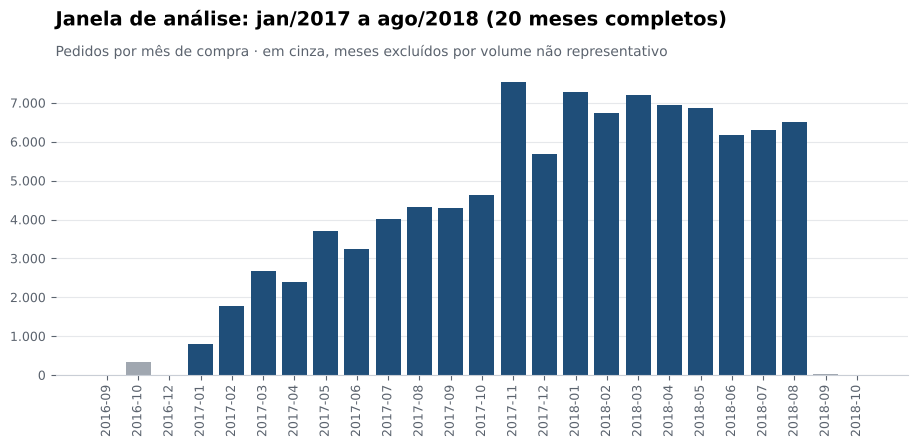

In [8]:
mensal = o.groupby(o["order_purchase_timestamp"].dt.to_period("M")).size()
fig, ax = plt.subplots(figsize=(11, 4))
cores = [COLORS["primary"] if (str(p) >= "2017-01" and str(p) <= "2018-08") else COLORS["neutral"]
         for p in mensal.index]
ax.bar(mensal.index.astype(str), mensal.values, color=cores)
ax.set_title("Janela de análise: jan/2017 a ago/2018 (20 meses completos)")
subtitle(ax, "Pedidos por mês de compra · em cinza, meses excluídos por volume não representativo")
ax.tick_params(axis="x", rotation=90)
axis_int(ax)
save(fig, "00_janela_analise")
plt.show()

**Decisão:** analisamos **jan/2017 a ago/2018**.
* 2016 tem apenas ~330 pedidos (fase de testes da operação, com um mês sem vendas).
* set e out/2018 têm 20 pedidos no total – a extração foi cortada, não é queda real de vendas.

Incluir esses meses distorceria crescimento e previsões.

## 5. Base analítica

In [9]:
base = build_items_base(t)
analise = base[base["is_valid"] & base["in_period"]]

resumo = pd.Series({
    "itens (base completa)": len(base),
    "itens na análise": len(analise),
    "pedidos na análise": analise["order_id"].nunique(),
    "clientes únicos": analise["customer_unique_id"].nunique(),
    "sellers ativos": analise["seller_id"].nunique(),
    "produtos vendidos": analise["product_id"].nunique(),
    "categorias": analise["product_category_name"].nunique(),
    "receita (R$, sem frete)": analise["price"].sum(),
    "frete (R$)": analise["freight_value"].sum(),
})
resumo.map(lambda v: f"{v:,.0f}".replace(",", "."))

itens (base completa)         112.650
itens na análise              111.752
pedidos na análise             97.905
clientes únicos                94.703
sellers ativos                  3.029
produtos vendidos              32.578
categorias                         74
receita (R$, sem frete)    13.449.530
frete (R$)                  2.234.177
dtype: str

In [10]:
cols = ["order_id", "order_item_id", "product_id", "seller_id", "price", "freight_value",
        "order_status", "order_purchase_timestamp", "month", "customer_unique_id",
        "customer_city", "customer_state", "customer_region", "product_category_name",
        "product_category_name_english", "seller_city", "seller_state", "seller_region"]
out = PROCESSED / "base_itens_analise.csv"
analise[cols].to_csv(out, index=False)
print(f"Base salva em data/processed/{out.name} – {len(analise):,} linhas x {len(cols)} colunas")

Base salva em data/processed/base_itens_analise.csv – 111,752 linhas x 18 colunas


## Conclusões de qualidade
1. **Dados íntegros:** chaves únicas, sem órfãos, sem valores negativos ou datas incoerentes.
2. **Regras documentadas:** receita = soma de `price` (sem frete) de pedidos não cancelados/indisponíveis;
   clientes contados por `customer_unique_id`; janela jan/2017–ago/2018.
3. **Base única e reproduzível:** todas as regras estão em `src/olist_utils.py` e são reaplicadas
   automaticamente em todos os notebooks.

➡️ Próximo: `02_evolucao_mensal_e_previsao.ipynb`